In [ ]:
# DATA MINING 1


# -----------------------------------------------
# -----------------------------------------------
# LIBRERIE

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, BisectingKMeans, OPTICS, cluster_optics_dbscan
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import seaborn as sns
import plotly.express as px
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '12'


# Stile generale per i grafici
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 4)

# CARICAMENTO DATAFRAME
df = pd.read_csv("/Users/ale/Documents/primo anno/dm1_25_26_dataset/df/DM1_game_dataset.csv")


# -----------------------------------------------
# -----------------------------------------------
# PULIZIA BASE E DEFINIZIONE GRUPPI DI COLONNE

print(f"\n----PULIZIA----")

df_cleaned = df.copy()
# Dropping delle variabili inutili
df_cleaned = df_cleaned.drop(["ComWeight", "LanguageEase", "BestPlayers", "GoodPlayers",
                              "ComMaxPlaytime", "NumComments", "ImagePath"], axis=1)
#Tolte ComWeight (uguale altra variabile), LanguageEase (non si capisce a cosa serva), BestPlayers (praticamente solo valori mancanti), GoodPlayers (come bestplayers),
# ComMaxPlaytime (= a mfgplaytime), NumComments (tutti 0), ImagePath")

# Filtro dei valori errati = 0 non imputabili
df_cleaned = df_cleaned[df_cleaned["YearPublished"] != 0]
df_cleaned = df_cleaned[df_cleaned["MinPlayers"] != 0]
df_cleaned = df_cleaned[df_cleaned["MaxPlayers"] != 0]

# Gestione NA di Family
df_cleaned["Family"] = df_cleaned["Family"].fillna("No_Family")

# Missing values di Gameweight
df_cleaned["GameWeight"] = df_cleaned["GameWeight"].replace(0, np.nan)

# IDEA CHIAVE: alla fine non abbiamo basi che ci permettono di rimuovere gli outliers tipo catan o Monopoli
# Però, possiamo pensare a year_published

# Colonna "Period"
condizione = [
    (df_cleaned['YearPublished'] < 1000),
    (df_cleaned['YearPublished'] >= 1000) & (
        df_cleaned['YearPublished'] < 1900),
    (df_cleaned['YearPublished'] >= 1900) & (
        df_cleaned['YearPublished'] < 2000),
    (df_cleaned['YearPublished'] >= 2000) & (
        df_cleaned['YearPublished'] < 2010),
    (df_cleaned['YearPublished'] >= 2010)
]
epoca = [
    'Pre_1000',
    '1000_1900',
    '1900_2000',
    '2000_2010',
    "2010_2021"
]
df_cleaned['Period'] = np.select(condizione, epoca, default=None)

# Colonna "Age"
df_cleaned['Age'] = 2025 - df_cleaned["YearPublished"]

# Qualitative
colonne_quali = df_cleaned.select_dtypes(include=["object"]).columns
colonne_quali = colonne_quali + ["BGGId"]

# Ranking
colonne_rank = [
    "Rank:strategygames", "Rank:abstracts", "Rank:familygames",
    "Rank:thematic", "Rank:cgs", "Rank:wargames",
    "Rank:partygames", "Rank:childrensgames"
]

# Categorie
colonne_cat = ["Cat:Thematic", "Cat:Strategy", "Cat:War", "Cat:Family",
               "Cat:CGS", "Cat:Abstract", "Cat:Party", "Cat:Childrens"]

# Binarie
colonne_binarie = ["Kickstarted", "IsReimplementation"]

# Quantitative
colonne_quanti = df_cleaned.select_dtypes(
    include=["int64", "float64"]).columns
colonne_quanti = colonne_quanti.drop([
    "BGGId"] + colonne_binarie
    + colonne_rank + colonne_cat)

# Numeriche
colonne_numeriche = (
    colonne_quanti.tolist() +
    colonne_rank +
    colonne_cat +
    colonne_binarie
)
colonne_numeriche = list(dict.fromkeys(colonne_numeriche))

# Creazione train_set e test_set per Data Leakage 
#da farmi spiegare cosa è stato fatto
train_set, test_set = train_test_split(
    df_cleaned, test_size=0.2, random_state=222)
train_set = train_set.copy()
test_set = test_set.copy()
print(f"\nDimensioni Train Set: {train_set.shape}")
print(f"\nDimensioni Test Set: {test_set.shape}")
 

# -----------------------------------------------
# -----------------------------------------------
# OUTLIERS

print(f"\n----OUTLIERS MODA----")

# Gestione missing con moda (valore di moda anche = a mediana quindi conveniente usare questo)
mode_mfg_playtime = train_set["MfgPlaytime"].mode()[0]
train_set["MfgPlaytime"] = train_set["MfgPlaytime"].replace(
    0, mode_mfg_playtime)
test_set["MfgPlaytime"] = test_set["MfgPlaytime"].replace(
    0, mode_mfg_playtime)

mode_com_playtime = train_set["ComMinPlaytime"].mode()[0]
train_set["ComMinPlaytime"] = train_set["ComMinPlaytime"].replace(
    0, mode_com_playtime)
test_set["ComMinPlaytime"] = test_set["ComMinPlaytime"].replace(
    0, mode_com_playtime)

# IMPUTAZIONE RANDOM FOREST
# Non c'è bisogno di scalare perchè gode di Invarianza Monotona

print(f"\n----OUTLIERS RANDOM FOREST----")

rf_estimator = RandomForestRegressor(
    n_estimators=22,
    random_state=222,
    n_jobs=-1
)

imputer_rf = IterativeImputer(
    estimator=rf_estimator,
    max_iter=10,
    random_state=222,
    verbose=2,               # 0 = silente, 1 = output, 2 = output dettagliato
    initial_strategy='median',
    add_indicator=False
)

df_numeric_to_impute = df_cleaned[colonne_numeriche].copy()

imputer_rf.fit(train_set[colonne_numeriche])
imputed_array_train = imputer_rf.transform(train_set[colonne_numeriche])
imputed_array_test = imputer_rf.transform(test_set[colonne_numeriche])

train_imputed = train_set.copy()
test_imputed = test_set.copy()

train_imputed[colonne_numeriche] = pd.DataFrame(
    imputed_array_train,
    columns=colonne_numeriche,
    index=train_imputed.index
)
test_imputed[colonne_numeriche] = pd.DataFrame(
    imputed_array_test,
    columns=colonne_numeriche,
    index=test_imputed.index
)


# -----------------------------------------------
# -----------------------------------------------
# TRASFORMAZIONE VARIABILI (SKEWNESS)

print(f"\n----TRASFORMAZIONE----")


def fit_trasformatore(dataframe: pd.DataFrame, colonne: list, soglia: float = 1.0):

    skew_values = dataframe[colonne].skew()
    colonne_da_trasformare = skew_values[abs(skew_values) > soglia].index

    col_log = []
    col_cbrt = []

    for col in colonne_da_trasformare:
        if dataframe[col].isnull().any():
            print(f"\n  - ATTENZIONE: '{col}' contiene NaN, non dovrebbe.")
            continue

        if dataframe[col].min() < 0:
            col_cbrt.append(col)
        else:
            col_log.append(col)

    if col_log:
        print(f"\n  - Trasformazione Logaritmica identificata per: {col_log}")
    if col_cbrt:
        print(
            f"\n  - Trasformazione Radice Cubica identificata per: {col_cbrt}")

    return col_log, col_cbrt


def apply_trasformatore(dataframe: pd.DataFrame, col_log: list, col_cbrt: list):
    df_copy = dataframe.copy()

    for col in col_log:
        if col in df_copy.columns:
            df_copy[col] = np.log1p(df_copy[col])

    for col in col_cbrt:
        if col in df_copy.columns:
            df_copy[col] = np.cbrt(df_copy[col])

    return df_copy


colonne_log, colonne_cbrt = fit_trasformatore(
    train_imputed, colonne_quanti.tolist())

train_transformed = apply_trasformatore(
    train_imputed, colonne_log, colonne_cbrt)
test_transformed = apply_trasformatore(test_imputed, colonne_log, colonne_cbrt)


# -----------------------------------------------
# -----------------------------------------------
# CORRELAZIONE

print("\n----CORRELAZIONE----")

# NON Trasformati
df_numeric_imputed = train_imputed.drop(
    ["BGGId", "Name", "Description", "Family", "Rating", "Period"], axis=1)

M_Cor_imputed = df_numeric_imputed.corr()

# Trasformati
df_numeric_transformed = train_transformed.drop(
    ["BGGId", "Name", "Description", "Family", "Rating", "Period"], axis=1)

M_Cor_transformed = df_numeric_transformed.corr()


# -----------------------------------------------
# -----------------------------------------------
# CLUSTERING

print("\n----CLUSTERING----")

X = train_transformed[colonne_numeriche]
y = np.array(train_transformed['Rating'])

scaler = MinMaxScaler()
X_minmax = scaler.fit_transform(X)

# -----------------------------------------------
# K-means
print("\n----CLUSTERING (K-Means)----")

kmeans = KMeans(n_clusters=5, n_init=10, max_iter=100, random_state=222)
kmeans.fit(X_minmax)

# -----------------------------------------------
# Bisecting K-means
print("\n----CLUSTERING (Bisecting K-Means)----")

bkmeans = BisectingKMeans(n_clusters=5, n_init=10,
                          max_iter=100, random_state=222)
bkmeans.fit(X_minmax)

# -----------------------------------------------
# DBscan
print("\n----CLUSTERING (DBscan)----")

dbscan = DBSCAN(eps=0.01, min_samples=10)
dbscan.fit(X_minmax)

# -----------------------------------------------
# Optics
print("\n----CLUSTERING (Optics)----")

optics = OPTICS(min_samples=20, max_eps=np.inf, min_cluster_size=10)
optics.fit(X_minmax)

# -----------------------------------------------
# Gerarchico
print("\n----CLUSTERING (Gerarchico)----")


def get_linkage_matrix(model):
    # Create linkage matrix

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    return linkage_matrix


def plot_dendrogram(model, **kwargs):
    linkage_matrix = get_linkage_matrix(model)
    dendrogram(linkage_matrix, **kwargs)


model = AgglomerativeClustering(distance_threshold=0, n_clusters=None,
                                metric='euclidean', linkage='complete')
model = model.fit(X_minmax)

# Finire pulizia                                        FATTO
# Scegliere variabili su cui fare clustering            DAFARE
# Giocare coi parametri di clustering                   DAFARE


----PULIZIA----

Dimensioni Train Set: (17251, 41)

Dimensioni Test Set: (4313, 41)

----OUTLIERS MODA----

----OUTLIERS RANDOM FOREST----
[IterativeImputer] Completing matrix with shape (17251, 35)
[IterativeImputer] Ending imputation round 1/10, elapsed time 6.13
[IterativeImputer] Change: 8.90909090909091, scaled tolerance: 166.497 
[IterativeImputer] Early stopping criterion reached.
[IterativeImputer] Completing matrix with shape (17251, 35)
[IterativeImputer] Ending imputation round 1/1, elapsed time 0.03
[IterativeImputer] Completing matrix with shape (4313, 35)
[IterativeImputer] Ending imputation round 1/1, elapsed time 0.03

----TRASFORMAZIONE----

  - Trasformazione Logaritmica identificata per: ['MinPlayers', 'MaxPlayers', 'NumOwned', 'NumWant', 'NumWish', 'NumWeightVotes', 'MfgPlaytime', 'ComMinPlaytime', 'NumUserRatings', 'NumAlternates', 'NumExpansions', 'NumImplementations', 'Age']

  - Trasformazione Radice Cubica identificata per: ['YearPublished']

----CORRELAZIONE-

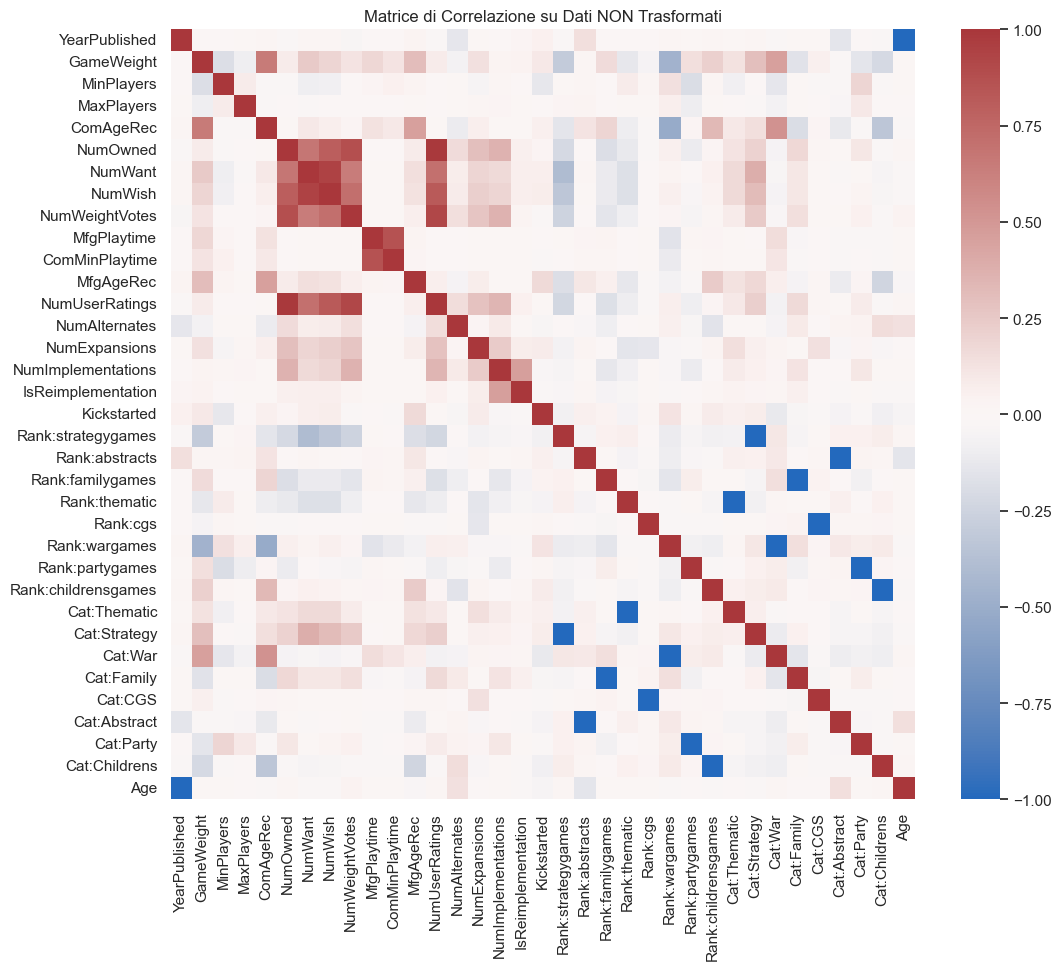

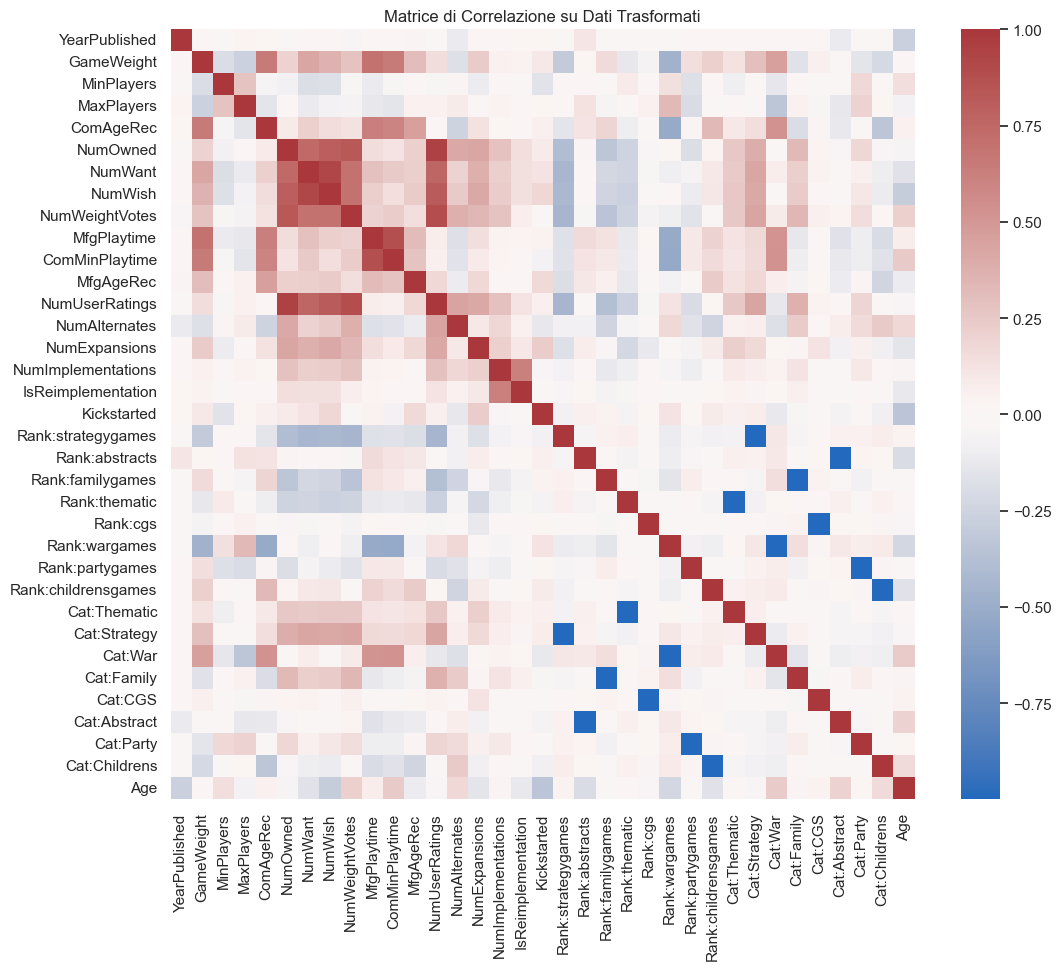

In [4]:
# Grafici Correlazione

plt.rcParams['figure.figsize'] = (8, 4)

plt.figure(figsize=(12, 10))
sns.heatmap(M_Cor_imputed, annot=False, cmap='vlag', fmt=".2f")
plt.title("Matrice di Correlazione su Dati NON Trasformati")
plt.show()

plt.figure(figsize=(12, 10))
sns.heatmap(M_Cor_transformed, annot=False, cmap='vlag', fmt=".2f")
plt.title("Matrice di Correlazione su Dati Trasformati")
plt.show()

CPU times: user 8min, sys: 3min 58s, total: 11min 58s
Wall time: 1min 11s


<Axes: >

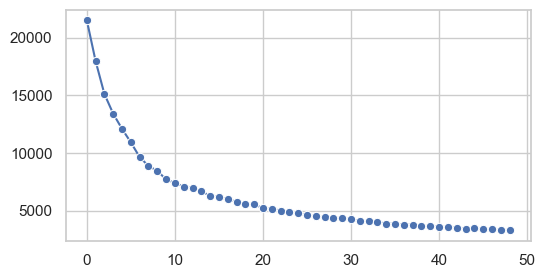

In [5]:
%%time
sse_list = []
plt.rcParams['figure.figsize'] = (6, 3)

for k in range(2, 51):
    kmeans = KMeans(n_clusters=k, n_init=10, max_iter=100, random_state = 42)
    kmeans.fit(X_minmax)
    sse_list.append(kmeans.inertia_)
    sse_list

sse_list
sns.lineplot(x=range(len(sse_list)), y=sse_list, marker='o')




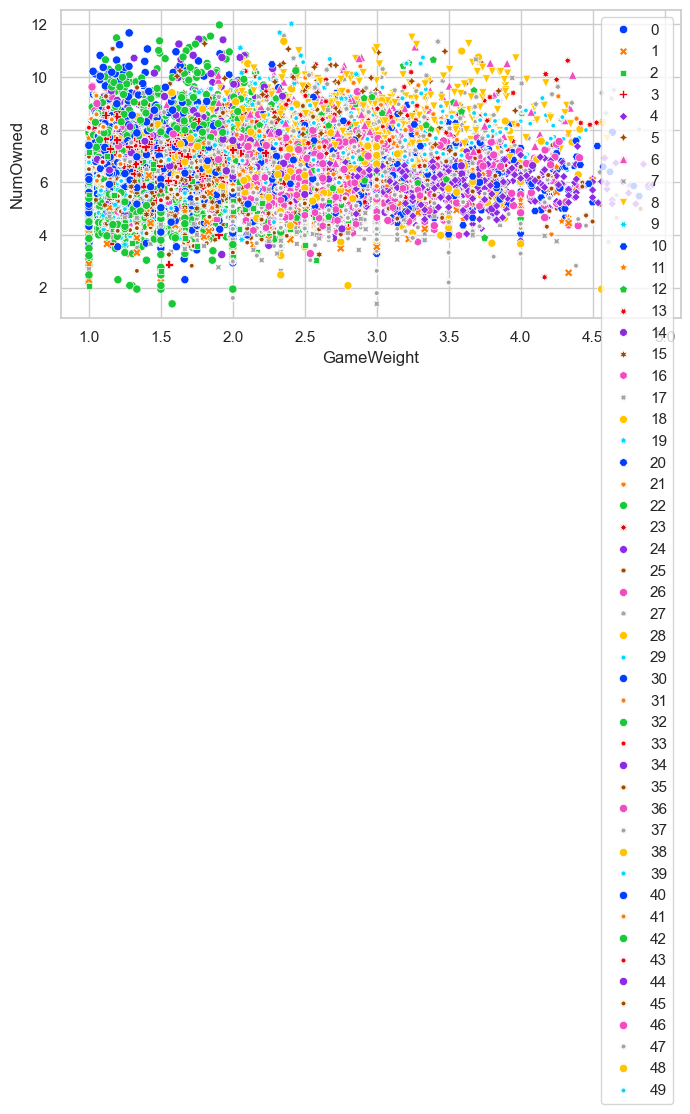

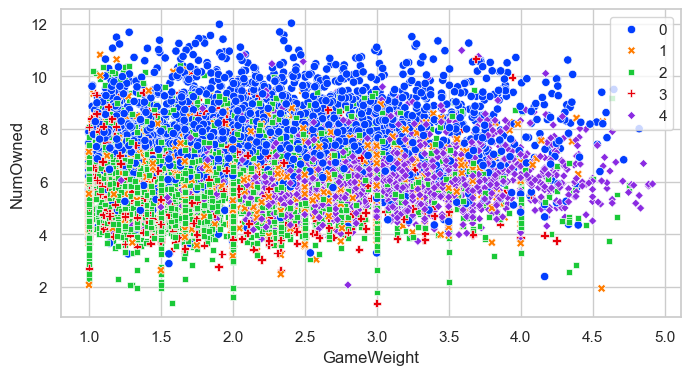

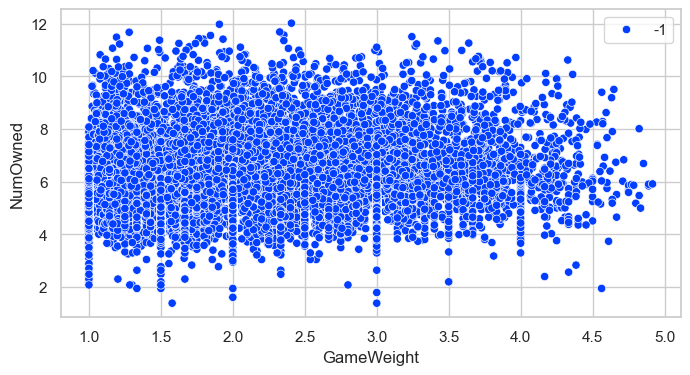

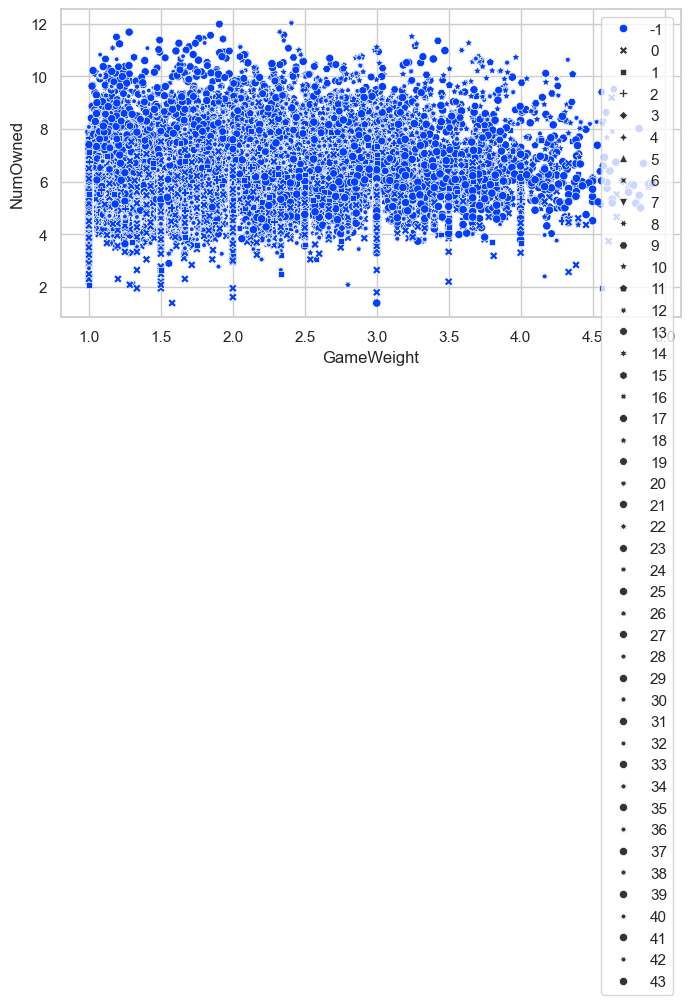

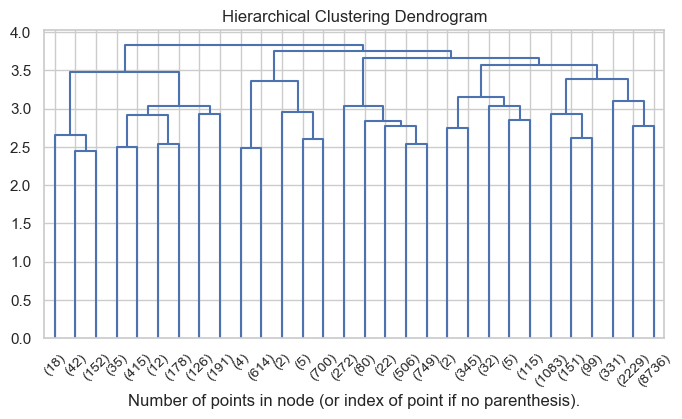

In [6]:
plt.rcParams['figure.figsize'] = (8, 4)

sns.scatterplot(data=train_transformed,
                x="GameWeight",
                y="NumOwned",
                hue=kmeans.labels_,
                style=kmeans.labels_,
                palette="bright")
plt.show()

sns.scatterplot(data=train_transformed,
                x="GameWeight",
                y="NumOwned",
                hue=bkmeans.labels_,
                style=bkmeans.labels_,
                palette="bright",
                )
plt.legend()
plt.show()


sns.scatterplot(data=train_transformed,
                x="GameWeight",
                y="NumOwned",
                hue=dbscan.labels_,
                style=dbscan.labels_,
                palette="bright")
plt.show()

sns.scatterplot(data=train_transformed,
                x="GameWeight",
                y="NumOwned",
                hue=dbscan.labels_,
                style=optics.labels_,
                palette="bright")
plt.show()


plt.title("Hierarchical Clustering Dendrogram")
plot_dendrogram(model, truncate_mode='lastp', color_threshold=0.7)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.show()